# Day 23 | Choose a Path or Run Two Tasks

**KGP Talkie**

Build parallel results, route a request, and keep input values.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

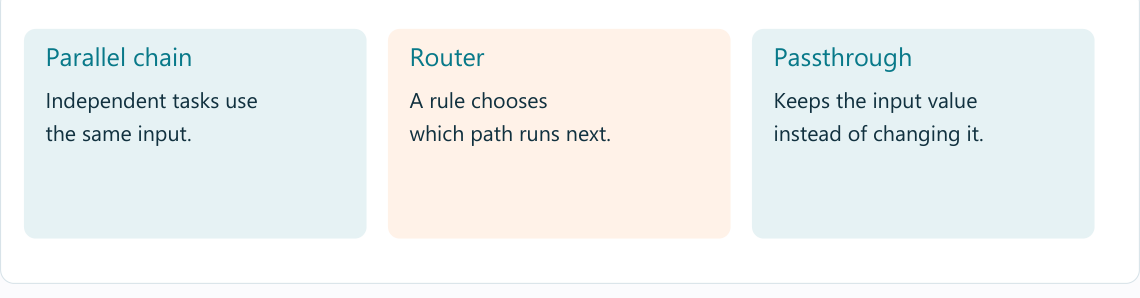

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 96-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=96, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

A chat prompt template fills named inputs and keeps message roles.

In [7]:
from langchain_core.prompts import ChatPromptTemplate

This parser reads reply content and returns a plain Python string.

In [8]:
from langchain_core.output_parsers import StrOutputParser

In [9]:
from langchain_core.runnables import RunnableParallel, RunnableLambda, RunnablePassthrough

In [10]:
facts = ChatPromptTemplate.from_template("Give one fact about {topic}.") | llm | StrOutputParser()

In [11]:
poem = ChatPromptTemplate.from_template("Write two short poem lines about {topic}.") | llm | StrOutputParser()

Independent branches share the input. Their results get different dictionary keys.

In [12]:
parallel = RunnableParallel(fact=facts, poem=poem)

In [13]:
print(parallel.invoke({"topic": "the sun"}))

{'fact': 'The sun is approximately 93 million miles (150 million kilometers) away from Earth, which is known as an astronomical unit (AU).', 'poem': 'Here are two short poem lines about the sun:\n\nGolden rays upon my skin,\nWarming heart and soul within.'}


In [14]:
positive = ChatPromptTemplate.from_template("Write a short thank-you for this review: {review}") | llm | StrOutputParser()

In [15]:
negative = ChatPromptTemplate.from_template("Write a short apology for this review: {review}") | llm | StrOutputParser()

Use known labels first so the path is visible. A classifier can supply labels later, but its mistakes must be checked.

In [16]:
def choose_route(values):
    if values["label"] == "positive":
        return positive
    if values["label"] == "negative":
        return negative
    raise ValueError("Use a known label: positive or negative.")

In [17]:
router = RunnableLambda(choose_route)

In [18]:
print(router.invoke({"label": "negative", "review": "The sound was unclear."}))

Here's a possible apology:

"I apologize if my previous review came across as dismissive or unhelpful regarding the audio quality of the product. My intention was simply to express that I had difficulty hearing certain details, but I understand how it could be misinterpreted. If you're considering purchasing this item, I would recommend checking out some reviews from other customers who may have a better experience with sound clarity."


In [19]:
print(router.invoke({"label": "positive", "review": "The lesson helped me."}))

Here's a possible response:

"Thank you so much for taking the time to share your experience with our lesson! We're thrilled to hear that it was helpful and made a positive impact on you. Your feedback is greatly appreciated and will help us continue to improve and provide valuable learning opportunities for others."


Passthrough keeps the original string; the other function counts whitespace-separated words.

In [20]:
counts = RunnableParallel(text=RunnablePassthrough(), words=RunnableLambda(lambda text: len(text.split())))

In [21]:
counts.invoke("Python helps us work with data.")

{'text': 'Python helps us work with data.', 'words': 6}

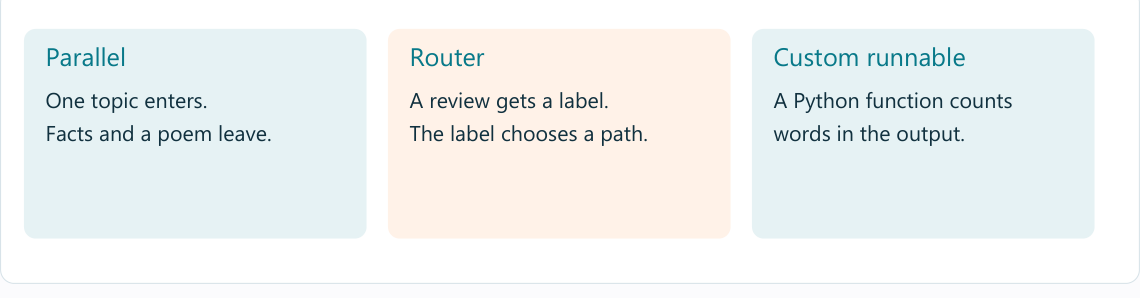

## Try a fresh input

Try a mixed review. Inspect the label before accepting the routed reply.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-chains).